<a href="https://colab.research.google.com/github/miso88oup/image-caption-generator/blob/main/notebooks/04_evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Image Caption Generator — Evaluation

Captions are generated for the 1,000 Flickr8k test images by every trained model (3 encoders × 3 seeds) using greedy search and beam search (k = 3, 5).

Metrics: BLEU-1 to 4, METEOR, ROUGE-L, CIDEr, caption diversity, repetition rate, and decoding time. Results are reported as mean ± standard deviation over the three seeds, and differences are tested with a paired bootstrap test.

## 1. Setup

In [1]:
!pip install -q pycocoevalcap

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 104.3/104.3 MB 7.8 MB/s eta 0:00:00


In [2]:
import os
import json
import time
import pickle

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import nltk
from PIL import Image
from tqdm.auto import tqdm
from tensorflow import keras
from nltk.translate.bleu_score import corpus_bleu
from nltk.translate.meteor_score import meteor_score
from pycocoevalcap.cider.cider import Cider
from pycocoevalcap.rouge.rouge import Rouge
from google.colab import drive

nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)
drive.mount('/content/drive')

PROJECT_DIR = '/content/drive/MyDrive/image-caption-project'
DATA_DIR = os.path.join(PROJECT_DIR, 'data')
FEATURES_DIR = os.path.join(PROJECT_DIR, 'features')
MODELS_DIR = os.path.join(PROJECT_DIR, 'models')
RESULTS_DIR = os.path.join(PROJECT_DIR, 'results')

print('GPU:', tf.config.list_physical_devices('GPU'))

Mounted at /content/drive
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
with open(os.path.join(DATA_DIR, 'captions_clean.json')) as f:
    captions = json.load(f)
with open(os.path.join(DATA_DIR, 'splits.json')) as f:
    splits = json.load(f)
with open(os.path.join(DATA_DIR, 'vocab.json')) as f:
    vocab = json.load(f)

word2idx = vocab['word2idx']
idx2word = {i: w for w, i in word2idx.items()}
max_length = vocab['max_length']
PAD, UNK = 0, 1
START, END = word2idx['startseq'], word2idx['endseq']

test_images = splits['test']
references = [[c.split()[1:-1] for c in captions[img]] for img in test_images]
train_captions = {' '.join(c.split()[1:-1]) for img in splits['train'] for c in captions[img]}

ENCODERS = ['vgg16', 'resnet50', 'inceptionv3']
SEEDS = [42, 7, 123]
DECODERS = {'greedy': 1, 'beam3': 3, 'beam5': 5}
BATCH = 128

print('Test images:', len(test_images))

Test images: 1000


## 2. Decoding

Both methods decode a batch of images at once. `<pad>`, `<unk>` and `startseq` are never generated. Beam search keeps the `k` most probable partial captions at each step and returns the one with the highest length-normalised log-probability. Beam search with k = 1 is identical to greedy search.

In [4]:
def next_word_probs(model, feats, seqs):
    probs = model([feats, seqs], training=False)[:, -1, :].numpy()
    probs[:, [PAD, UNK, START]] = 0.0
    return probs


def to_words(seq):
    words = []
    for i in seq[1:]:
        if i in (END, PAD):
            break
        words.append(idx2word[int(i)])
    return words


def beam_search(model, feats, k):
    n = len(feats)
    feats_k = np.repeat(feats, k, axis=0)
    seqs = np.full((n, k, 1), START)
    scores = np.full((n, k), -np.inf)
    scores[:, 0] = 0.0
    finished = np.zeros((n, k), dtype=bool)

    for _ in range(max_length - 1):
        probs = next_word_probs(model, feats_k, seqs.reshape(n * k, -1))
        log_probs = np.log(probs + 1e-12).reshape(n, k, -1)
        vocab_size = log_probs.shape[-1]

        # a finished caption can only be extended with padding, at no cost
        log_probs[finished] = -np.inf
        log_probs[..., PAD] = np.where(finished, 0.0, -np.inf)

        total = (scores[:, :, None] + log_probs).reshape(n, -1)
        top = np.argsort(-total, axis=1)[:, :k]
        beam_idx, word_idx = top // vocab_size, top % vocab_size

        scores = np.take_along_axis(total, top, axis=1)
        seqs = np.take_along_axis(seqs, beam_idx[:, :, None], axis=1)
        seqs = np.concatenate([seqs, word_idx[:, :, None]], axis=2)
        finished = np.take_along_axis(finished, beam_idx, axis=1) | (word_idx == END)
        if finished.all():
            break

    lengths = np.maximum((seqs[:, :, 1:] != PAD).sum(axis=2), 1)
    best = (scores / lengths).argmax(axis=1)
    return [to_words(seqs[i, best[i]]) for i in range(n)]


def generate(model, feats, k):
    out = []
    for i in range(0, len(feats), BATCH):
        out += beam_search(model, feats[i:i + BATCH], k)
    return out

## 3. Generate Test Captions

In [5]:
generated, timing = {}, {}

for name in ENCODERS:
    with open(os.path.join(FEATURES_DIR, f'{name}.pkl'), 'rb') as f:
        features = pickle.load(f)
    test_feats = np.stack([features[img] for img in test_images]).astype('float32')
    del features

    for seed in SEEDS:
        model = keras.models.load_model(os.path.join(MODELS_DIR, f'{name}_seed{seed}.keras'))

        for method, k in DECODERS.items():
            generated[(name, seed, method)] = generate(model, test_feats, k)

            if seed == SEEDS[0]:
                start = time.perf_counter()
                for j in range(50):
                    generate(model, test_feats[j:j + 1], k)
                timing[(name, method)] = (time.perf_counter() - start) / 50 * 1000

        print(f'{name} seed {seed} done')
        del model
        keras.backend.clear_session()

vgg16 seed 42 done
vgg16 seed 7 done
vgg16 seed 123 done
resnet50 seed 42 done
resnet50 seed 7 done
resnet50 seed 123 done
inceptionv3 seed 42 done
inceptionv3 seed 7 done
inceptionv3 seed 123 done


## 4. Metrics

In [6]:
BLEU_WEIGHTS = {
    'BLEU-1': (1, 0, 0, 0),
    'BLEU-2': (0.5, 0.5, 0, 0),
    'BLEU-3': (1/3, 1/3, 1/3, 0),
    'BLEU-4': (0.25, 0.25, 0.25, 0.25),
}
gts = {i: [' '.join(r) for r in refs] for i, refs in enumerate(references)}


def has_repeat(words, n=3):
    grams = [tuple(words[i:i + n]) for i in range(len(words) - n + 1)]
    return len(grams) != len(set(grams))


def score(hyps):
    res = {i: [' '.join(h) if h else 'a'] for i, h in enumerate(hyps)}
    cider, cider_per_image = Cider().compute_score(gts, res)
    rouge, _ = Rouge().compute_score(gts, res)

    metrics = {m: corpus_bleu(references, hyps, weights=w) for m, w in BLEU_WEIGHTS.items()}
    metrics['METEOR'] = np.mean([meteor_score(refs, h) for refs, h in zip(references, hyps)])
    metrics['ROUGE-L'] = rouge
    metrics['CIDEr'] = cider
    metrics['Avg length'] = np.mean([len(h) for h in hyps])
    metrics['Vocab used'] = len({w for h in hyps for w in h})
    metrics['Novel (%)'] = 100 * np.mean([' '.join(h) not in train_captions for h in hyps])
    metrics['Repetition (%)'] = 100 * np.mean([has_repeat(h) for h in hyps])
    return metrics, np.array(cider_per_image)


rows, cider_images = [], {}
for (name, seed, method), hyps in tqdm(generated.items()):
    metrics, per_image = score(hyps)
    rows.append({'Encoder': name, 'Seed': seed, 'Decoding': method, **metrics})
    cider_images[(name, seed, method)] = per_image

per_run = pd.DataFrame(rows)
per_run.to_csv(os.path.join(RESULTS_DIR, 'metrics_per_run.csv'), index=False)

  0%|          | 0/27 [00:00<?, ?it/s]

## 5. Results (mean ± std over 3 seeds)

In [7]:
METRICS = list(BLEU_WEIGHTS) + ['METEOR', 'ROUGE-L', 'CIDEr']
EXTRA = ['Avg length', 'Vocab used', 'Novel (%)', 'Repetition (%)']

grouped = per_run.groupby(['Encoder', 'Decoding'], sort=False)
mean, std = grouped[METRICS + EXTRA].mean(), grouped[METRICS + EXTRA].std()

summary = mean.round(4).astype(str) + ' ± ' + std.round(4).astype(str)
summary['Time / caption (ms)'] = [round(timing[key], 1) for key in summary.index]

mean.round(4).to_csv(os.path.join(RESULTS_DIR, 'metrics_mean.csv'))
std.round(4).to_csv(os.path.join(RESULTS_DIR, 'metrics_std.csv'))
summary.to_csv(os.path.join(RESULTS_DIR, 'results_table.csv'))
summary[METRICS]

BLEU-1           BLEU-2           BLEU-3  \
Encoder     Decoding                                                      
vgg16       greedy    0.5767 ± 0.0083  0.3952 ± 0.0071  0.2577 ± 0.0068   
            beam3     0.5928 ± 0.0045  0.4108 ± 0.0034  0.2759 ± 0.0026   
            beam5     0.5932 ± 0.0045  0.4133 ± 0.0051  0.2804 ± 0.0058   
resnet50    greedy    0.6038 ± 0.0096  0.4188 ± 0.0084  0.2815 ± 0.0072   
            beam3     0.6092 ± 0.0035  0.4303 ± 0.0026  0.2966 ± 0.0036   
            beam5      0.6055 ± 0.003  0.4269 ± 0.0036   0.2941 ± 0.004   
inceptionv3 greedy    0.5943 ± 0.0028  0.4119 ± 0.0027  0.2761 ± 0.0026   
            beam3     0.6069 ± 0.0058  0.4265 ± 0.0052  0.2941 ± 0.0032   
            beam5     0.6013 ± 0.0038  0.4216 ± 0.0038  0.2909 ± 0.0024   

                               BLEU-4           METEOR          ROUGE-L  \
Encoder     Decoding                                                      
vgg16       greedy    0.1673 ± 0.0059  0.3836 ± 0.0014   0.438 ± 0.0025   
            beam3     0.1839 ± 0.0009  0.4036 ± 0.0035  0.4482 ± 0.0009   
            beam5     0.1883 ± 0.0045   0.409 ± 0.0032  0.4504 ± 0.0014   
resnet50    greedy    0.1881 ± 0.0066  0.4017 ± 0.0045   0.4549 ± 0.004   
            beam3     0.2025 ± 0.0038  0.4194 ± 0.0021  0.4642 ± 0.0005   
            beam5     0.2001 ± 0.0037  0.4202 ± 0.0032   0.4616 ± 0.002   
inceptionv3 greedy    0.1823 ± 0.0033  0.3988 ± 0.0026   0.4502 ± 0.004   
            beam3      0.1997 ± 0.001  0.4161 ± 0.0039  0.4601 ± 0.0032   
            beam5     0.1974 ± 0.0012  0.4162 ± 0.0038  0.4583 ± 0.0034   

                                CIDEr  
Encoder     Decoding                   
vgg16       greedy    0.4414 ± 0.0074  
            beam3     0.4762 ± 0.0058  
            beam5     0.4879 ± 0.0011  
resnet50    greedy    0.4905 ± 0.0143  
            beam3     0.5249 ± 0.0062  
            beam5     0.5195 ± 0.0047  
inceptionv3 greedy     0.475 ± 0.0051  
            beam3     0.5137 ± 0.0087  
            beam5      0.512 ± 0.0112

In [8]:
summary[EXTRA + ['Time / caption (ms)']]

Avg length          Vocab used         Novel (%)  \
Encoder     Decoding                                                           
vgg16       greedy    10.6057 ± 0.2003         353.0 ± 3.0     91.9 ± 1.6371   
            beam3     10.8883 ± 0.1991   333.6667 ± 7.5056  91.9667 ± 2.0133   
            beam5     10.9893 ± 0.1229     339.0 ± 14.9332     91.7 ± 2.0664   
resnet50    greedy     10.382 ± 0.3152   351.6667 ± 9.2916   90.9667 ± 1.106   
            beam3     10.8167 ± 0.1809   340.3333 ± 3.7859  91.5667 ± 0.2517   
            beam5     10.9523 ± 0.1596      338.0 ± 7.2111  91.6667 ± 0.7638   
inceptionv3 greedy    10.4777 ± 0.1625         384.0 ± 1.0  92.4667 ± 1.0599   
            beam3     10.8153 ± 0.2562  376.6667 ± 12.0139  92.6333 ± 0.4163   
            beam5     10.9603 ± 0.2478  374.3333 ± 13.6504  92.3667 ± 0.9074   

                       Repetition (%)  Time / caption (ms)  
Encoder     Decoding                                        
vgg16       greedy       7.5 ± 2.1656                225.1  
            beam3        6.1 ± 1.3454                263.2  
            beam5        5.7 ± 1.3115                287.2  
resnet50    greedy    5.5333 ± 2.7062                227.2  
            beam3     5.1333 ± 1.5567                251.3  
            beam5        4.8 ± 1.2166                272.2  
inceptionv3 greedy       6.2 ± 0.8718                201.9  
            beam3     4.8333 ± 0.0577                237.6  
            beam5     4.5667 ± 0.5033                244.8

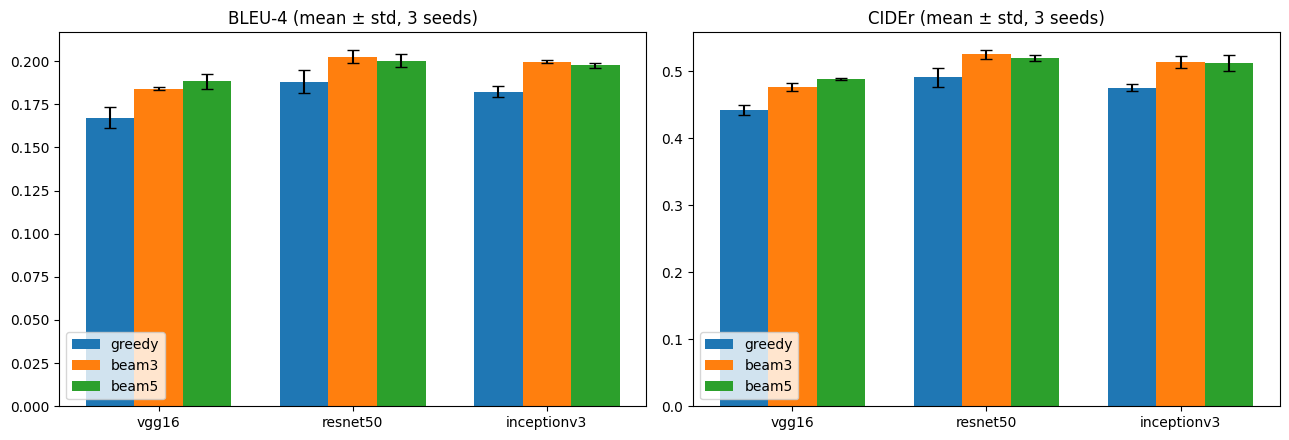

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
x = np.arange(len(ENCODERS))
width = 0.25

for ax, metric in zip(axes, ['BLEU-4', 'CIDEr']):
    for j, method in enumerate(DECODERS):
        m = [mean.loc[(e, method), metric] for e in ENCODERS]
        s = [std.loc[(e, method), metric] for e in ENCODERS]
        ax.bar(x + (j - 1) * width, m, width, yerr=s, capsize=4, label=method)
    ax.set_xticks(x)
    ax.set_xticklabels(ENCODERS)
    ax.set_title(f'{metric} (mean ± std, 3 seeds)')
    ax.legend()

plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'metrics_comparison.png'), dpi=150, bbox_inches='tight')
plt.show()

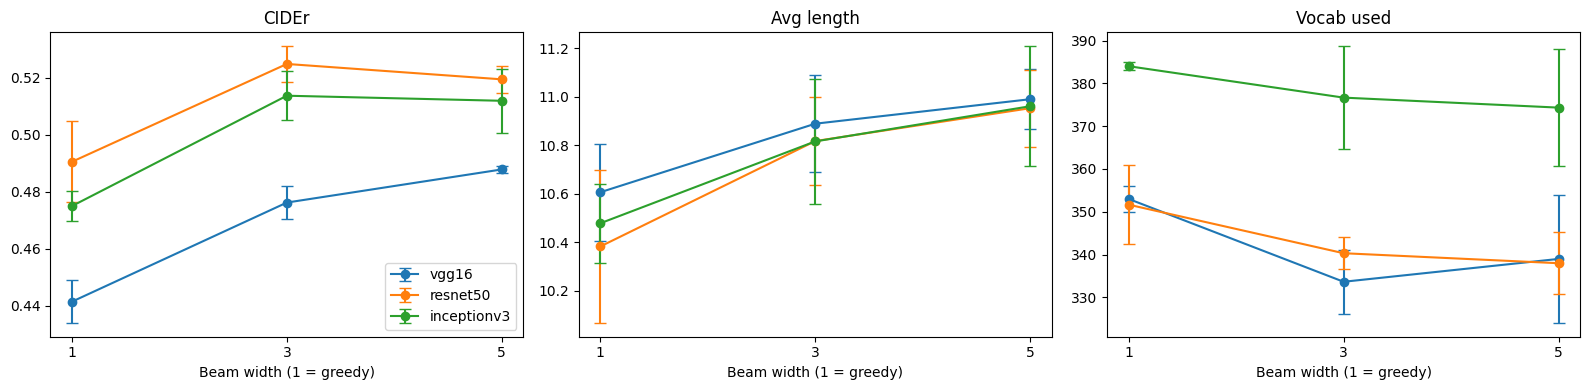

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
widths = list(DECODERS.values())

for name in ENCODERS:
    for ax, metric in zip(axes, ['CIDEr', 'Avg length', 'Vocab used']):
        ax.errorbar(widths, [mean.loc[(name, m), metric] for m in DECODERS],
                    yerr=[std.loc[(name, m), metric] for m in DECODERS],
                    marker='o', capsize=4, label=name)
        ax.set_title(metric)
        ax.set_xlabel('Beam width (1 = greedy)')
        ax.set_xticks(widths)

axes[0].legend()
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'beam_width_effect.png'), dpi=150, bbox_inches='tight')
plt.show()

## 6. Significance Testing

Paired bootstrap test on per-image CIDEr (averaged over seeds), 10,000 resamples of the test images. A p-value below 0.05 means the difference is unlikely to be due to which test images happened to be chosen.

In [11]:
def image_cider(name, method):
    return np.mean([cider_images[(name, seed, method)] for seed in SEEDS], axis=0)


def paired_bootstrap(a, b, n_resamples=10000, seed=0):
    rng = np.random.default_rng(seed)
    diff = a - b
    idx = rng.integers(0, len(diff), size=(n_resamples, len(diff)))
    boot = diff[idx].mean(axis=1)
    p = 2 * min((boot <= 0).mean(), (boot >= 0).mean())
    low, high = np.percentile(boot, [2.5, 97.5])
    return diff.mean(), low, high, min(p, 1.0)


comparisons = []
for method in DECODERS:
    for i, a in enumerate(ENCODERS):
        for b in ENCODERS[i + 1:]:
            comparisons.append((f'{a} vs {b}', method, image_cider(a, method), image_cider(b, method)))
for name in ENCODERS:
    for method in ['beam3', 'beam5']:
        comparisons.append((f'{name}: {method} vs greedy', '-', image_cider(name, method), image_cider(name, 'greedy')))

sig_rows = []
for label, method, a, b in comparisons:
    d, low, high, p = paired_bootstrap(a, b)
    sig_rows.append({'Comparison': label, 'Decoding': method, 'CIDEr diff': round(d, 4),
                     '95% CI': f'[{low:.4f}, {high:.4f}]', 'p-value': round(p, 4), 'Significant': p < 0.05})

significance = pd.DataFrame(sig_rows)
significance.to_csv(os.path.join(RESULTS_DIR, 'significance.csv'), index=False)
significance

,Comparison,Decoding,CIDEr diff,95% CI,p-value,Significant
0,vgg16 vs resnet50,greedy,-0.0491,"[-0.0690, -0.0302]",0.0000,True
1,vgg16 vs inceptionv3,greedy,-0.0336,"[-0.0545, -0.0127]",0.0026,True
2,resnet50 vs inceptionv3,greedy,0.0155,"[-0.0033, 0.0345]",0.1126,False
3,vgg16 vs resnet50,beam3,-0.0487,"[-0.0700, -0.0278]",0.0000,True
4,vgg16 vs inceptionv3,beam3,-0.0375,"[-0.0592, -0.0160]",0.0006,True
5,resnet50 vs inceptionv3,beam3,0.0112,"[-0.0088, 0.0307]",0.2754,False
6,vgg16 vs resnet50,beam5,-0.0316,"[-0.0531, -0.0106]",0.0040,True
7,vgg16 vs inceptionv3,beam5,-0.0241,"[-0.0454, -0.0035]",0.0202,True
8,resnet50 vs inceptionv3,beam5,0.0075,"[-0.0121, 0.0271]",0.4562,False
9,vgg16: beam3 vs greedy,-,0.0348,"[0.0233, 0.0462]",0.0000,True


## 7. Generated Captions (seed 42)

In [12]:
table = pd.DataFrame({'image': test_images, 'reference': [' '.join(r[0]) for r in references]})
for name in ENCODERS:
    for method in DECODERS:
        table[f'{name}_{method}'] = [' '.join(h) for h in generated[(name, SEEDS[0], method)]]

table.to_csv(os.path.join(RESULTS_DIR, 'test_captions.csv'), index=False)
table.head(10)

,image,reference,vgg16_greedy,vgg16_beam3,vgg16_beam5,resnet50_greedy,resnet50_beam3,resnet50_beam5,inceptionv3_greedy,inceptionv3_beam3,inceptionv3_beam5
0,3385593926_d3e9c21170.jpg,the dogs are in the snow in front of a fence,two brown dogs are running in the snow,two brown dogs are running in the snow,two brown dogs are running in the snow,a brown dog is running through the snow,a brown dog is playing in the snow,two brown dogs are playing in the snow,a brown dog is running on a snowy path,a brown dog is running through the snow,a brown dog is running through the snow
1,2677656448_6b7e7702af.jpg,a brown and white dog swimming towards some in...,a dog is playing with a ball in a pool,a small white and white dog is playing with a ...,a brown and white dog is playing with a ball i...,a small boy is playing in the water,a little boy is playing in a pool,a little boy is playing in a pool,a dog is jumping into a pool while a man watches,a brown and white dog is jumping into a swimmi...,a brown and white dog is jumping into a swimmi...
2,311146855_0b65fdb169.jpg,a man and a woman in festive costumes dancing,a man in a blue shirt and a blue shirt is hold...,a man in a blue shirt is holding a baby in a b...,a man in a blue shirt is holding a baby in a b...,a man in a blue shirt and a blue shirt is stan...,a man in a blue shirt and a blue shirt is stan...,a man in a blue shirt and a blue shirt is stan...,a man in a blue shirt is standing in front of ...,a man in a blue shirt is standing in front of ...,a man in a blue shirt is standing in front of ...
3,1258913059_07c613f7ff.jpg,a couple of people sit outdoors at a table wit...,a man in a red jacket is standing on a bench i...,a man in a red jacket is standing in front of ...,a man in a red jacket is standing in front of ...,a man is sitting on a bench in front of a buil...,a man and a woman are sitting on a bench in fr...,a man and a woman are sitting on a bench in fr...,a group of people are sitting on a balcony,a group of people are sitting on a sidewalk in...,a group of people are sitting on a sidewalk in...
4,241347760_d44c8d3a01.jpg,a man is wearing a sooners red football shirt ...,a football player in a red jersey is being tac...,a football player in a red jersey is holding a...,a football player in a red jersey is holding a...,a football player in a red jersey is being tac...,a football player in a red jersey is wearing a...,a football player in a red jersey is holding a...,a football player in a red uniform is running ...,a football player in a red and white uniform i...,a football player in a red uniform is holding ...
5,2654514044_a70a6e2c21.jpg,a brown dog running,a brown dog is running through a grassy field,a brown dog is running through the grass with ...,a brown dog runs through the grass with a toy ...,a brown dog is running through the grass,a brown dog is running through the grass,a brown dog is running through the grass,a brown dog runs through the grass,a brown dog is running through the grass,a brown dog is running through the grass
6,2339106348_2df90aa6a9.jpg,a girl with dark brown hair and eyes in a blue...,a woman with a mohawk and a woman in a red shirt,a woman in a black shirt is holding a cigarette,a woman in a black shirt is holding a cigarette,a woman in a black shirt and a woman in a crowd,a group of people are posing for a picture,a group of people posing for a picture,a group of people wearing black and white unif...,a group of young women wearing black and white...,a group of asian women are posing for a pictur...
7,256085101_2c2617c5d0.jpg,a dog with its mouth opened,a brown and white dog is playing with a tennis...,a brown and white dog is playing with a tennis...,a brown and white dog is playing with a tennis...,a brown and white dog is licking its nose,a brown and white dog is licking its nose,a brown and white dog is licking its nose,a brown and white dog is licking its nose,a brown and white dog is licking its nose,a brown and white dog is lick

## 8. Qualitative Examples

Best configuration by mean CIDEr. Images are ranked by per-image CIDEr (seed 42).

Best configuration: resnet50 beam3
Using Colab cache for faster access to the 'flickr8k' dataset.


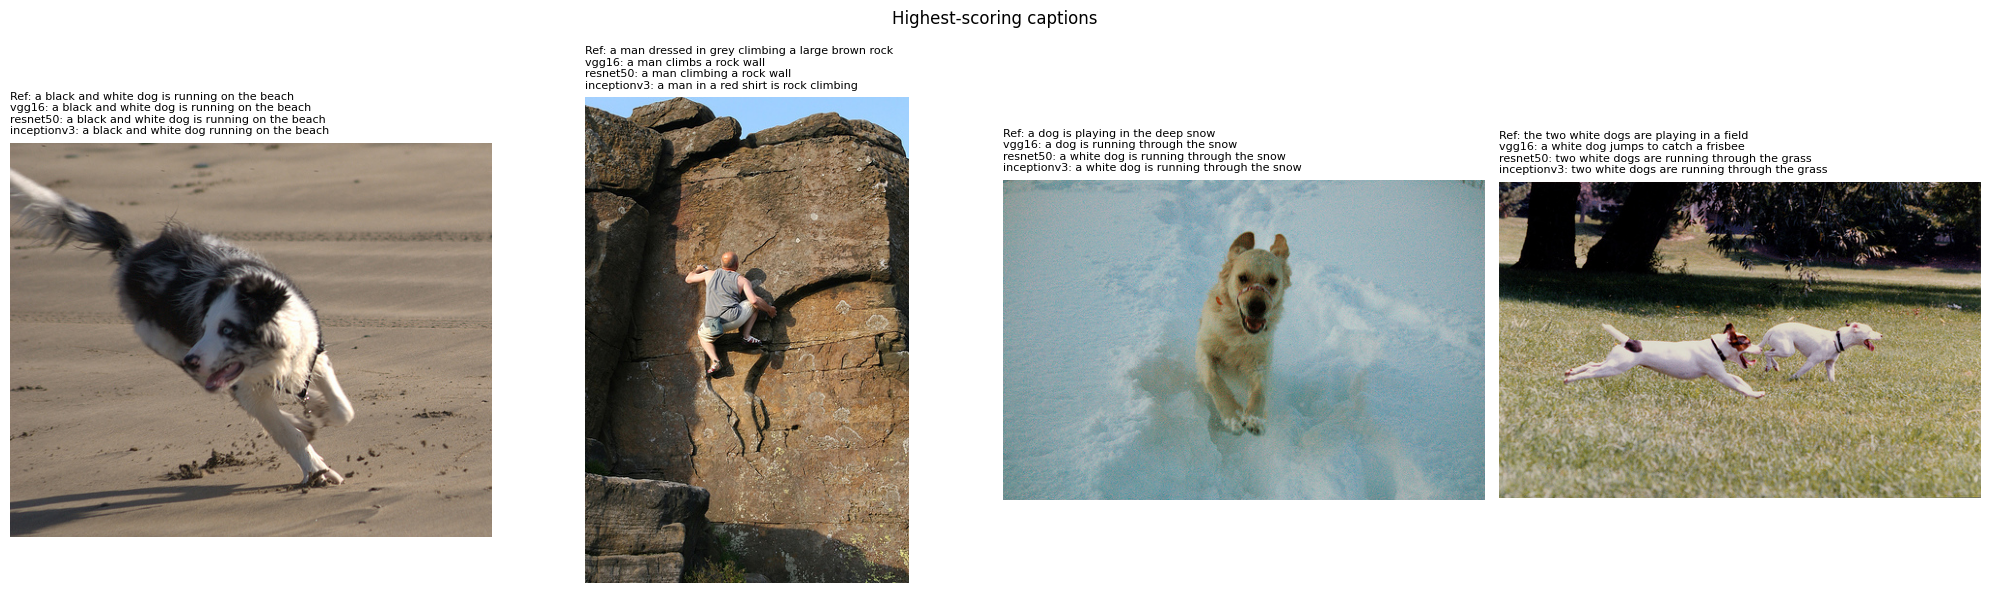

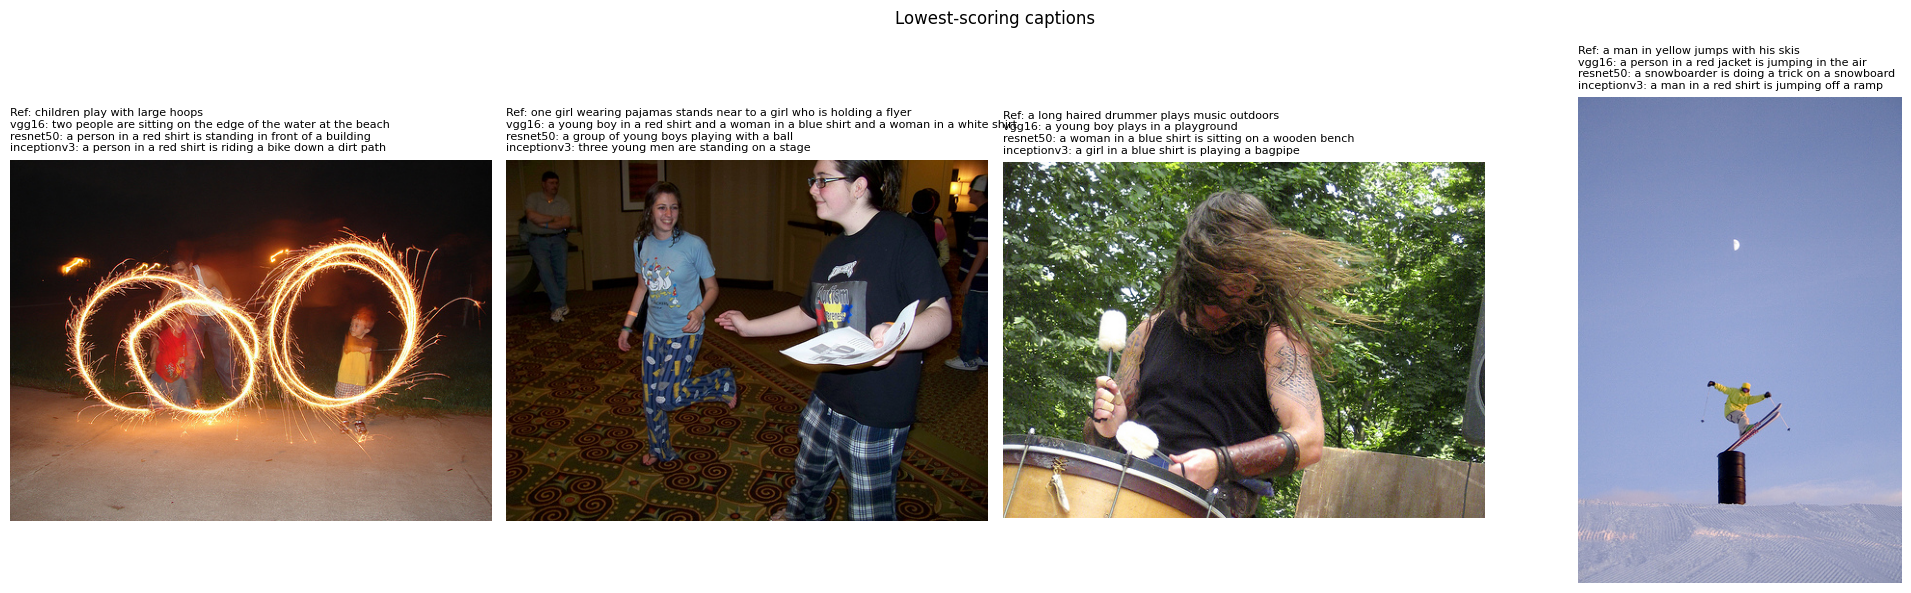

In [13]:
best_enc, best_method = mean['CIDEr'].idxmax()
print('Best configuration:', best_enc, best_method)

order = np.argsort(cider_images[(best_enc, SEEDS[0], best_method)])

import kagglehub
IMAGE_DIR = os.path.join(kagglehub.dataset_download('adityajn105/flickr8k'), 'Images')


def show_examples(indices, title, filename):
    fig, axes = plt.subplots(1, len(indices), figsize=(5 * len(indices), 6))
    for ax, i in zip(axes, indices):
        ax.imshow(Image.open(os.path.join(IMAGE_DIR, test_images[i])))
        ax.axis('off')
        text = 'Ref: ' + ' '.join(references[i][0])
        for name in ENCODERS:
            text += f"\n{name}: {' '.join(generated[(name, SEEDS[0], best_method)][i])}"
        ax.set_title(text, fontsize=8, loc='left')
    fig.suptitle(title)
    plt.tight_layout()
    plt.savefig(os.path.join(RESULTS_DIR, filename), dpi=150, bbox_inches='tight')
    plt.show()


show_examples(order[-4:][::-1], 'Highest-scoring captions', 'examples_good.png')
show_examples(order[:4], 'Lowest-scoring captions', 'examples_poor.png')

In [14]:
repeats = [(test_images[i], ' '.join(h)) for i, h in enumerate(generated[(best_enc, SEEDS[0], best_method)]) if has_repeat(h)]
print(f'{len(repeats)} captions with a repeated phrase, e.g.:')
for img, cap in repeats[:8]:
    print(f'  {img}: {cap}')

66 captions with a repeated phrase, e.g.:
  311146855_0b65fdb169.jpg: a man in a blue shirt and a blue shirt is standing in front of a crowd
  241347760_d44c8d3a01.jpg: a football player in a red jersey is wearing a red jersey
  241347204_007d83e252.jpg: a football player in a red jersey is being tackled by a football player
  510531976_90bbee22a2.jpg: a man in a white shirt and a white shirt is sitting on a wooden bench
  2762301555_48a0d0aa24.jpg: a little girl in a blue shirt and a blue shirt is standing on a sidewalk
  3647750811_395fbd397e.jpg: a black and white dog is playing with a black and white dog
  2731171552_4a808c7d5a.jpg: a man in a white shirt and a white shirt is standing on the beach
  3554634863_5f6f616639.jpg: a crowd of people are sitting in a crowd of people
